# Archived v1 results: what survives the guess bug

The first E1–E4 runs treated a wrong `GUESS:` naming a listed candidate as a formatting
error and retried it **within the same turn**. Wrong guesses were free and leaked
"not this one" feedback. Those logs are in `archive/guess-bug-v1/` and are being re-run
under the v2 rule.

This notebook evaluates only what the old data can still support:

* **Clean games** contain no *visible* hidden wrong guess. They are what the corrected rule
  would have produced (with v1 prompts), so their outcomes are exact, with one caveat below.
* **Affected games** diverge at the first hidden guess, so their outcomes are unknown. The
  true win rate lies between counting them all as losses (lower bound) and all as wins
  (upper bound).
* Measures not driven by guess handling (question repetition, invalid moves, answerer
  behavior, applied flips) are reported directly.

**Logging caveat.** v1 recorded the guesser's attempts only on guess and invalid-move
turns. A wrong guess retried *before a question* left no trace, so some "clean" games were
affected too. Replaying v1 games under the fixed rule (same prompts and seeds) found
**11 of 102 visibly clean Qwen3 games differed, versus 0 of 64 Gemma games**. Bounds are
therefore approximate for Qwen3 and Granite. For Gemma and Mistral, the "exact" status is
supported by the replay evidence but can't be proven from the v1 logs alone. Current runs
log guesser attempts on every turn (`raw_moves`).

The numbers come from `src/analysis/v1_salvage.py`, the same code that writes
`reports/v1-salvage.md`. Use the kernel **llmat20qs analysis**.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "analysis").is_dir())
sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from src.analysis import v1_salvage as v1

pd.set_option("display.float_format", "{:.2f}".format)
rows = v1.load_rows()
games = pd.DataFrame([row for study_rows in rows.values() for row in study_rows])
summary = v1.evaluate()
games.groupby("study").size().rename("games").to_frame()

,games
study,
E1 cross-play,480
E1 self-play,160
E2 predictable,640
E2 scouting (partial),553
E3 liar (partial),231
E4 noisy,300


In [2]:
# Chart style: reference palette, fixed model order (registry order), recessive axes.
MODELS = ["qwen3-8b", "gemma3-12b-it", "mistral-nemo-12b", "granite-3.3-8b"]
LABELS = {"qwen3-8b": "Qwen3 8B", "gemma3-12b-it": "Gemma 3 12B",
          "mistral-nemo-12b": "Mistral Nemo 12B", "granite-3.3-8b": "Granite 3.3 8B"}
COLORS = dict(zip(MODELS, ["#257de0", "#f47230", "#00b894", "#f2a600"]))
INK, INK2, GRID = "#191919", "#666666", "#e7e7e7"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "axes.edgecolor": GRID,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
})

def by_guesser(study):
    table = pd.DataFrame(summary["studies"][study]["by_guesser"]).T
    return table.reindex([m for m in MODELS if m in table.index])

## 1. Guesser win rates: reported vs. what the data supports

Each bar spans the **possible true win rate** under the corrected rule. A bar collapsed to a
point (a solid colored dot) means no game was affected and the result is exact. The white dot is the v1
reported value.

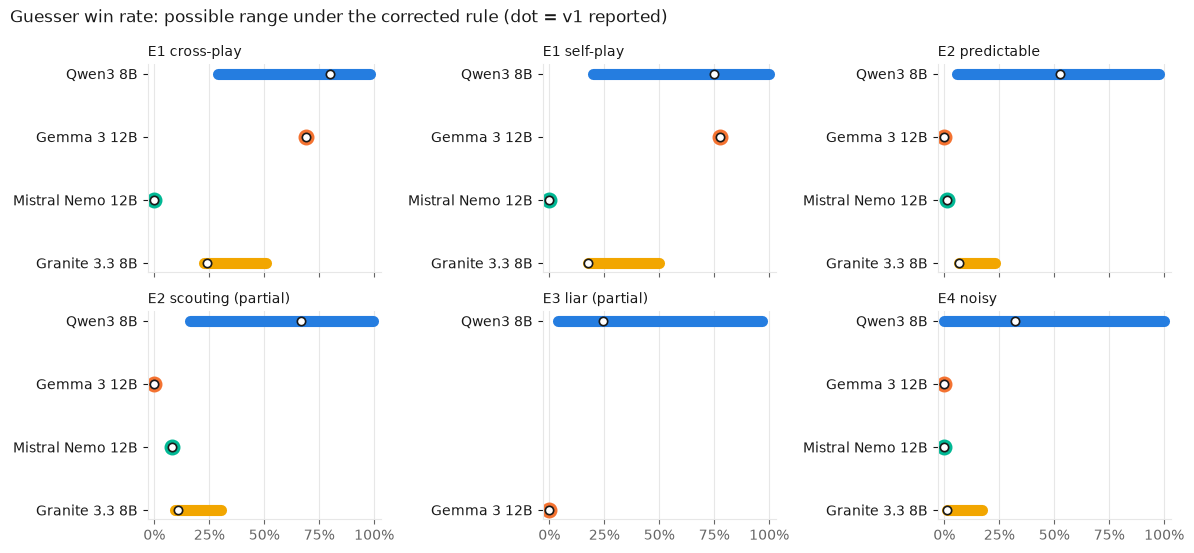

In [3]:
studies = list(summary["studies"])
fig, axes = plt.subplots(2, 3, figsize=(12, 5.6), sharex=True)
for ax, study in zip(axes.flat, studies):
    table = by_guesser(study)
    for y, (model, s) in enumerate(table.iterrows()):
        low, high = s["win_rate_lower_bound"], s["win_rate_upper_bound"]
        ax.plot([low, high], [y, y], color=COLORS[model], linewidth=8,
                solid_capstyle="round", zorder=2)
        if high - low < 1e-9:  # exact result: a zero-width range draws nothing
            ax.scatter([low], [y], s=110, color=COLORS[model], zorder=2)
        ax.scatter([s["reported_v1_win_rate"]], [y], s=36, color="white",
                   edgecolor=INK, linewidth=1.2, zorder=3)
    ax.set_yticks(range(len(table)), [LABELS[m] for m in table.index])
    ax.invert_yaxis()
    ax.set_xlim(-0.03, 1.03)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_title(study, loc="left", fontsize=10, color=INK)
    ax.grid(axis="y", visible=False)
fig.suptitle("Guesser win rate: possible range under the corrected rule (dot = v1 reported)",
             x=0.01, ha="left", fontsize=12)
fig.tight_layout()
plt.show()

In [4]:
columns = ["games", "reported_v1_win_rate", "win_rate_lower_bound", "win_rate_upper_bound",
           "clean_games", "affected_games", "median_divergence_turn"]
pd.concat({study: by_guesser(study)[columns] for study in studies}).rename(index=LABELS)

games  reported_v1_win_rate  \
E1 cross-play         Qwen3 8B         120.00                  0.80   
                      Gemma 3 12B      120.00                  0.69   
                      Mistral Nemo 12B 120.00                  0.00   
                      Granite 3.3 8B   120.00                  0.24   
E1 self-play          Qwen3 8B          40.00                  0.75   
                      Gemma 3 12B       40.00                  0.78   
                      Mistral Nemo 12B  40.00                  0.00   
                      Granite 3.3 8B    40.00                  0.17   
E2 predictable        Qwen3 8B         160.00                  0.53   
                      Gemma 3 12B      160.00                  0.00   
                      Mistral Nemo 12B 160.00                  0.01   
                      Granite 3.3 8B   160.00                  0.07   
E2 scouting (partial) Qwen3 8B         160.00                  0.67   
                      Gemma 3 12B      160.00                  0.00   
                      Mistral Nemo 12B 160.00                  0.08   
                      Granite 3.3 8B    73.00                  0.11   
E3 liar (partial)     Qwen3 8B         126.00                  0.25   
                      Gemma 3 12B      105.00                  0.00   
E4 noisy              Qwen3 8B          75.00                  0.32   
                      Gemma 3 12B       75.00                  0.00   
                      Mistral Nemo 12B  75.00                  0.00   
                      Granite 3.3 8B    75.00                  0.01   

                                        win_rate_lower_bound  \
E1 cross-play         Qwen3 8B                          0.29   
                      Gemma 3 12B                       0.69   
                      Mistral Nemo 12B                  0.00   
                      Granite 3.3 8B                    0.23   
E1 self-play          Qwen3 8B                          0.20   
                      Gemma 3 12B                       0.78   
                      Mistral Nemo 12B                  0.00   
                      Granite 3.3 8B                    0.17   
E2 predictable        Qwen3 8B                          0.06   
                      Gemma 3 12B                       0.00   
                      Mistral Nemo 12B                  0.01   
                      Granite 3.3 8B                    0.07   
E2 scouting (partial) Qwen3 8B                          0.16   
                      Gemma 3 12B                       0.00   
                      Mistral Nemo 12B                  0.08   
                      Granite 3.3 8B                    0.10   
E3 liar (partial)     Qwen3 8B                          0.04   
                      Gemma 3 12B                       0.00   
E4 noisy              Qwen3 8B                          0.00   
                      Gemma 3 12B                       0.00   
                      Mistral Nemo 12B                  0.00   
                      Granite 3.3 8B                    0.01   

                                        win_rate_upper_bound  clean_games  \
E1 cross-play         Qwen3 8B                          0.98        37.00   
                      Gemma 3 12B                       0.69       120.00   
                      Mistral Nemo 12B                  0.00       120.00   
                      Granite 3.3 8B                    0.51        86.00   
E1 self-play          Qwen3 8B                          1.00         8.00   
                      Gemma 3 12B                       0.78        40.00   
                      Mistral Nemo 12B                  0.00        40.00   
                      Granite 3.3 8B                    0.50        27.00   
E2 predictable        Qwen3 8B                          0.97        13.00   
                      Gemma 3 12B                       0.00       160.00   
                      Mistral Nemo 12B                  0.01       160.00   
         

**Reading it**

* Gemma and Mistral show no hidden wrong guesses, and Gemma's replayed games so far are
  identical to v1, so their v1 numbers are **effectively exact**. That
  includes Gemma's 69–78% in E1 and its 0% in E2–E4: it really never commits to a guess
  among 128 candidates. The re-runs keep the same prompts and seeds, so these two models'
  E1 games should closely reproduce v1, which is a check on the re-run.
* Granite is moderately affected, with ranges of roughly 20–30 points.
* Qwen3 is unrankable from v1: most of its games are affected, and the range spans almost
  0–100% in the follow-ups. The `clean_game_win_rate` in the JSON is **not** an estimate
  for Qwen3. Clean games are selected on Qwen guessing right the first time.

## 2. How early does the bug kick in?

The turn of the first hidden wrong guess in affected games. Early divergence means little
of the game is comparable to the corrected protocol.

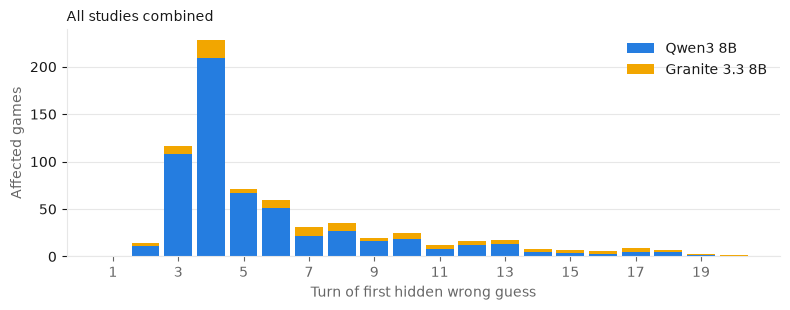

,count,25%,50%,75%
guesser,,,,
Granite 3.3 8B,100.00,4.00,7.00,11.25
Qwen3 8B,587.00,4.00,4.00,6.00


In [5]:
affected = games[~games["clean"]]
fig, ax = plt.subplots(figsize=(8, 3.2))
bins = [turn - 0.5 for turn in range(1, 22)]  # center each bar on its turn
stack = [affected.loc[affected["guesser"] == m, "divergence_turn"] for m in MODELS]
present = [(m, s) for m, s in zip(MODELS, stack) if len(s)]
ax.hist([s for _, s in present], bins=bins, stacked=True, rwidth=0.85,
        color=[COLORS[m] for m, _ in present], label=[LABELS[m] for m, _ in present])
ax.set_xlabel("Turn of first hidden wrong guess")
ax.set_ylabel("Affected games")
ax.set_xticks(range(1, 21, 2))
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, loc="upper right")
ax.set_title("All studies combined", loc="left", fontsize=10)
fig.tight_layout()
plt.show()
affected.groupby("guesser")["divergence_turn"].describe()[["count", "25%", "50%", "75%"]].rename(index=LABELS)

## 3. Question repetition (unaffected by the bug)

The share of a guesser's questions that repeat an earlier question in the same game
(normalized text).

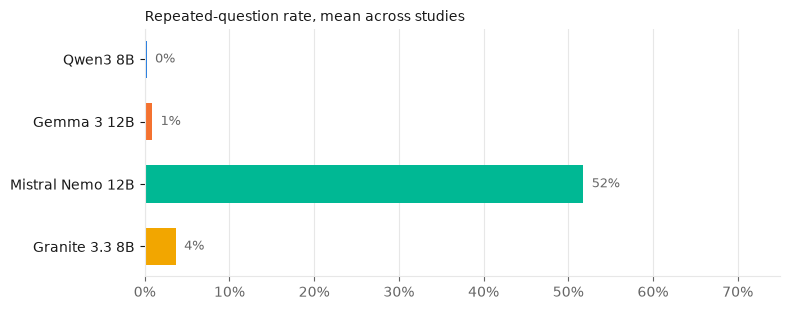

study,E1 cross-play,E1 self-play,E2 predictable,E2 scouting (partial),E3 liar (partial),E4 noisy
guesser,,,,,,
Qwen3 8B,0%,0%,0%,1%,0%,0%
Gemma 3 12B,0%,0%,1%,1%,1%,2%
Mistral Nemo 12B,36%,36%,62%,59%,nan%,65%
Granite 3.3 8B,2%,6%,3%,4%,nan%,3%


In [6]:
rep = (games.groupby(["guesser", "study"])[["repeated_questions", "questions"]].sum()
       .assign(rate=lambda d: d["repeated_questions"] / d["questions"])["rate"].unstack())
rep = rep.reindex([m for m in MODELS if m in rep.index])[studies]
fig, ax = plt.subplots(figsize=(8, 3.2))
values = rep.mean(axis=1)
ax.barh(range(len(values)), values.values, color=[COLORS[m] for m in values.index],
        height=0.6)
for y, v in enumerate(values.values):
    ax.text(v + 0.01, y, f"{v:.0%}", va="center", color=INK2, fontsize=9)
ax.set_yticks(range(len(values)), [LABELS[m] for m in values.index])
ax.invert_yaxis()
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlim(0, max(0.75, values.max() + 0.08))
ax.grid(axis="y", visible=False)
ax.set_title("Repeated-question rate, mean across studies", loc="left", fontsize=10)
fig.tight_layout()
plt.show()
rep.rename(index=LABELS).style.format("{:.0%}")

Mistral's near-zero win rate is explained by looping: 36% of its E1 questions and about 60%
of its follow-up questions are repeats ("Is it a person?", "Is it an animal?"). The
other models rarely repeat.

## 4. Answerer behavior

Yes-rate among valid answers and invalid answers per game. Without an answer key this is
descriptive only. Granite's low Yes-rate in some studies is worth checking against labels
later.

In [7]:
ans = pd.concat({study: pd.DataFrame(summary["studies"][study]["by_answerer"]).T
                 [["games", "answerer_yes_rate", "invalid_answers_per_game"]]
                 for study in studies})
ans.rename(index=LABELS)

games  answerer_yes_rate  \
E1 cross-play         Gemma 3 12B      120.00               0.37   
                      Granite 3.3 8B   120.00               0.41   
                      Mistral Nemo 12B 120.00               0.34   
                      Qwen3 8B         120.00               0.38   
E1 self-play          Gemma 3 12B       40.00               0.51   
                      Granite 3.3 8B    40.00               0.18   
                      Mistral Nemo 12B  40.00               0.37   
                      Qwen3 8B          40.00               0.37   
E2 predictable        Gemma 3 12B      160.00               0.38   
                      Granite 3.3 8B   160.00               0.29   
                      Mistral Nemo 12B 160.00               0.33   
                      Qwen3 8B         160.00               0.37   
E2 scouting (partial) Gemma 3 12B      160.00               0.45   
                      Granite 3.3 8B    73.00               0.15   
                      Mistral Nemo 12B 160.00               0.52   
                      Qwen3 8B         160.00               0.34   
E3 liar (partial)     Qwen3 8B         231.00               0.32   
E4 noisy              Qwen3 8B         300.00               0.35   

                                        invalid_answers_per_game  
E1 cross-play         Gemma 3 12B                           0.00  
                      Granite 3.3 8B                        0.02  
                      Mistral Nemo 12B                      0.00  
                      Qwen3 8B                              0.00  
E1 self-play          Gemma 3 12B                           0.00  
                      Granite 3.3 8B                        0.15  
                      Mistral Nemo 12B                      0.00  
                      Qwen3 8B                              0.00  
E2 predictable        Gemma 3 12B                           0.00  
                      Granite 3.3 8B                        0.05  
                      Mistral Nemo 12B                      0.00  
                      Qwen3 8B                              0.00  
E2 scouting (partial) Gemma 3 12B                           0.00  
                      Granite 3.3 8B                        0.10  
                      Mistral Nemo 12B                      0.00  
                      Qwen3 8B                              0.00  
E3 liar (partial)     Qwen3 8B                              0.00  
E4 noisy              Qwen3 8B                              0.00

## 5. Condition breakdowns (E2 scouting, E3, E4)

Bounds per guesser × condition. With the bug, these comparisons can't separate the
conditions: only Gemma and Mistral rows are exact, and those are all at or near 0%. They
are included for completeness and as a baseline for the v2 re-runs.

In [8]:
for study in studies:
    entry = summary["studies"][study]
    if "by_guesser_condition" not in entry:
        continue
    table = pd.DataFrame(entry["by_guesser_condition"]).T
    table.index = pd.MultiIndex.from_tuples([tuple(k.split(" | ")) for k in table.index],
                                            names=["guesser", "condition"])
    print(study)
    display(table[["games", "win_rate_lower_bound", "win_rate_upper_bound",
                   "clean_games", "mean_applied_flips"]].rename(index=LABELS, level=0))

E2 scouting (partial)


games  win_rate_lower_bound  \
guesser          condition                                      
Gemma 3 12B      no report        80.00                  0.00   
                 scouting report  80.00                  0.00   
Granite 3.3 8B   no report        73.00                  0.10   
Mistral Nemo 12B no report        80.00                  0.06   
                 scouting report  80.00                  0.10   
Qwen3 8B         no report        80.00                  0.03   
                 scouting report  80.00                  0.30   

                                  win_rate_upper_bound  clean_games  \
guesser          condition                                            
Gemma 3 12B      no report                        0.00        80.00   
                 scouting report                  0.00        80.00   
Granite 3.3 8B   no report                        0.30        58.00   
Mistral Nemo 12B no report                        0.06        80.00   
                 scouting report                  0.10        80.00   
Qwen3 8B         no report                        0.99         3.00   
                 scouting report                  1.00        24.00   

                                  mean_applied_flips  
guesser          condition                            
Gemma 3 12B      no report                      0.00  
                 scouting report                0.00  
Granite 3.3 8B   no report                      0.00  
Mistral Nemo 12B no report                      0.00  
                 scouting report                0.00  
Qwen3 8B         no report                      0.00  
                 scouting report                0.00

E3 liar (partial)


games  win_rate_lower_bound  \
guesser     condition                                      
Gemma 3 12B lies=0,unwarned  21.00                  0.00   
            lies=0,warned    21.00                  0.00   
            lies=1,unwarned  21.00                  0.00   
            lies=1,warned    21.00                  0.00   
            lies=2,unwarned  11.00                  0.00   
            lies=2,warned    10.00                  0.00   
Qwen3 8B    lies=0,unwarned  21.00                  0.05   
            lies=0,warned    21.00                  0.00   
            lies=1,unwarned  21.00                  0.05   
            lies=1,warned    21.00                  0.05   
            lies=2,unwarned  21.00                  0.05   
            lies=2,warned    21.00                  0.05   

                             win_rate_upper_bound  clean_games  \
guesser     condition                                            
Gemma 3 12B lies=0,unwarned                  0.00        21.00   
            lies=0,warned                    0.00        21.00   
            lies=1,unwarned                  0.00        21.00   
            lies=1,warned                    0.00        21.00   
            lies=2,unwarned                  0.00        11.00   
            lies=2,warned                    0.00        10.00   
Qwen3 8B    lies=0,unwarned                  0.95         2.00   
            lies=0,warned                    0.95         1.00   
            lies=1,unwarned                  1.00         1.00   
            lies=1,warned                    0.95         2.00   
            lies=2,unwarned                  1.00         1.00   
            lies=2,warned                    0.95         2.00   

                             mean_applied_flips  
guesser     condition                            
Gemma 3 12B lies=0,unwarned                0.00  
            lies=0,warned                  0.00  
            lies=1,unwarned                1.00  
            lies=1,warned                  1.00  
            lies=2,unwarned                2.00  
            lies=2,warned                  2.00  
Qwen3 8B    lies=0,unwarned                0.00  
            lies=0,warned                  0.00  
            lies=1,unwarned                0.43  
            lies=1,warned                  0.57  
            lies=2,unwarned                1.24  
            lies=2,warned                  1.33

E4 noisy


games  win_rate_lower_bound  win_rate_upper_bound  \
guesser          condition                                                      
Gemma 3 12B      flip=10%   25.00                  0.00                  0.00   
                 flip=17%   25.00                  0.00                  0.00   
                 flip=5%    25.00                  0.00                  0.00   
Granite 3.3 8B   flip=10%   25.00                  0.00                  0.12   
                 flip=17%   25.00                  0.04                  0.20   
                 flip=5%    25.00                  0.00                  0.20   
Mistral Nemo 12B flip=10%   25.00                  0.00                  0.00   
                 flip=17%   25.00                  0.00                  0.00   
                 flip=5%    25.00                  0.00                  0.00   
Qwen3 8B         flip=10%   25.00                  0.00                  1.00   
                 flip=17%   25.00                  0.00                  1.00   
                 flip=5%    25.00                  0.00                  1.00   

                            clean_games  mean_applied_flips  
guesser          condition                                   
Gemma 3 12B      flip=10%         25.00                1.76  
                 flip=17%         25.00                3.52  
                 flip=5%          25.00                0.88  
Granite 3.3 8B   flip=10%         22.00                1.52  
                 flip=17%         21.00                3.04  
                 flip=5%          20.00                0.96  
Mistral Nemo 12B flip=10%         25.00                1.92  
                 flip=17%         25.00                3.32  
                 flip=5%          25.00                1.04  
Qwen3 8B         flip=10%          0.00                1.36  
                 flip=17%          0.00                2.20  
                 flip=5%           0.00                0.76

## Takeaways

1. **Valid from v1:** Gemma and Mistral outcomes (exact); Granite within bounds; question
   repetition; answerer Yes-rates; applied flip counts.
2. **Not valid from v1:** any Qwen3 win rate, and every condition comparison in E2–E4.
3. **For the v2 re-runs:** prompts and sampling seeds are unchanged, so Gemma's and
   Mistral's E1 results should closely reproduce the exact v1 values above. A large
   difference would point to nondeterminism or a pipeline change, not a model effect.